Install a library


In [40]:
%pip install xgboost
%pip install lightgbm
%pip install numpy
%pip install pandas
%pip install scikit-learn
%pip install seaborn
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Import a library

In [41]:
from sklearn.base import clone
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)



Read a dataset from csv file

In [42]:

train_transaction = pd.read_csv("data/train_transaction.csv")
train_identity    = pd.read_csv("data/train_identity.csv")
test_transaction  = pd.read_csv("data/test_transaction.csv")
test_identity     = pd.read_csv("data/test_identity.csv")




In [43]:
test_identity.columns = [c.replace("id-", "id_") for c in test_identity.columns]

merge transaction and identity data to train and test set

In [44]:


train_dataset = pd.merge(train_transaction, train_identity, on= 'TransactionID', how = 'left' )
test_dataset = pd.merge(test_transaction, test_identity, on= 'TransactionID', how = 'left' )

Shape of dataset

In [45]:
#shape of the train and test set
print(f'Train dataset has {train_dataset.shape[0]} rows and {train_dataset.shape[1]} columns.')
print(f'Test dataset has {train_dataset.shape[0]} rows and {train_dataset.shape[1]} columns.')

Train dataset has 590540 rows and 434 columns.
Test dataset has 590540 rows and 434 columns.


Short view of dataset

In [46]:
train_dataset.head(10)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
5,2987005,0,86510,49.0,W,5937,555.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2987006,0,86522,159.0,W,12308,360.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987007,0,86529,422.5,W,12695,490.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2987008,0,86535,15.0,H,2803,100.0,150.0,visa,226.0,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
9,2987009,0,86536,117.0,W,17399,111.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [47]:
test_dataset.head(10)

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3663551,18403310,171.00,W,4476,574.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3663552,18403310,284.95,W,10989,360.0,150.0,visa,166.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3663553,18403317,67.95,W,18018,452.0,150.0,mastercard,117.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,3663554,18403323,57.95,W,12839,321.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,3663555,18403350,87.00,W,16560,476.0,150.0,visa,126.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,3663556,18403387,390.00,W,15066,170.0,150.0,mastercard,102.0,credit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,3663557,18403405,103.95,W,2803,100.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,3663558,18403416,117.00,W,12544,321.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


missing value for each column

In [48]:
missing = train_dataset.isnull().sum().sort_values(ascending= False)
missing.head(20)

id_24    585793
id_25    585408
id_07    585385
id_08    585385
id_21    585381
id_26    585377
id_27    585371
id_23    585371
id_22    585371
dist2    552913
D7       551623
id_18    545427
D13      528588
D14      528353
D12      525823
id_04    524216
id_03    524216
D6       517353
id_33    517251
id_09    515614
dtype: int64

info for train and test dataset


In [49]:
train_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), str(31)
memory usage: 1.9 GB


In [50]:
test_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 506691 entries, 0 to 506690
Columns: 433 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(3), str(31)
memory usage: 1.7 GB


using describe() to view a distribution of dataset

In [51]:
train_dataset.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,id_17,id_18,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_32
count,5.905400e+05,590540.000000,5.905400e+05,590540.000000,590540.000000,581607.000000,588975.000000,586281.000000,524834.000000,524834.000000,...,139369.000000,45113.000000,139318.000000,139261.000000,5159.000000,5169.000000,4747.000000,5132.000000,5163.000000,77586.000000
mean,3.282270e+06,0.034990,7.372311e+06,135.027176,9898.734658,362.555488,153.194925,199.278897,290.733794,86.800630,...,189.451377,14.237337,353.128174,403.882666,368.269820,16.002708,12.800927,329.608924,149.070308,26.508597
std,1.704744e+05,0.183755,4.617224e+06,239.162522,4901.170153,157.793246,11.336444,41.244453,101.741072,2.690623,...,30.375360,1.561302,141.095343,152.160327,198.847038,6.897665,2.372447,97.461089,32.101995,3.737502
min,2.987000e+06,0.000000,8.640000e+04,0.251000,1000.000000,100.000000,100.000000,100.000000,100.000000,10.000000,...,100.000000,10.000000,100.000000,100.000000,100.000000,10.000000,11.000000,100.000000,100.000000,0.000000
25%,3.134635e+06,0.000000,3.027058e+06,43.321000,6019.000000,214.000000,150.000000,166.000000,204.000000,87.000000,...,166.000000,13.000000,266.000000,256.000000,252.000000,14.000000,11.000000,321.000000,119.000000,24.000000
50%,3.282270e+06,0.000000,7.306528e+06,68.769000,9678.000000,361.000000,150.000000,226.000000,299.000000,87.000000,...,166.000000,15.000000,341.000000,472.000000,252.000000,14.000000,11.000000,321.000000,149.000000,24.000000
75%,3.429904e+06,0.000000,1.124662e+07,125.000000,14184.000000,512.000000,150.000000,226.000000,330.000000,87.000000,...,225.000000,15.000000,427.000000,533.000000,486.500000,14.000000,15.000000,371.000000,169.000000,32.000000
max,3.577539e+06,1.000000,1.581113e+07,31937.391000,18396.000000,600.000000,231.000000,237.000000,540.000000,102.000000,...,229.000000,29.000000,671.000000,661.000000,854.000000,44.000000,26.000000,548.000000,216.000000,32.000000


Unique value 

In [52]:
one_value_cols = [col for col in train_dataset.columns if train_dataset[col].nunique() <= 1]
one_value_cols_test = [col for col in test_dataset.columns if test_dataset[col].nunique() <= 1]
print(f'There are {len(one_value_cols)} columns in train dataset with one unique value.')
print(f'There are {len(one_value_cols_test)} columns in test dataset with one unique value.')

There are 0 columns in train dataset with one unique value.
There are 1 columns in test dataset with one unique value.


Data visualization


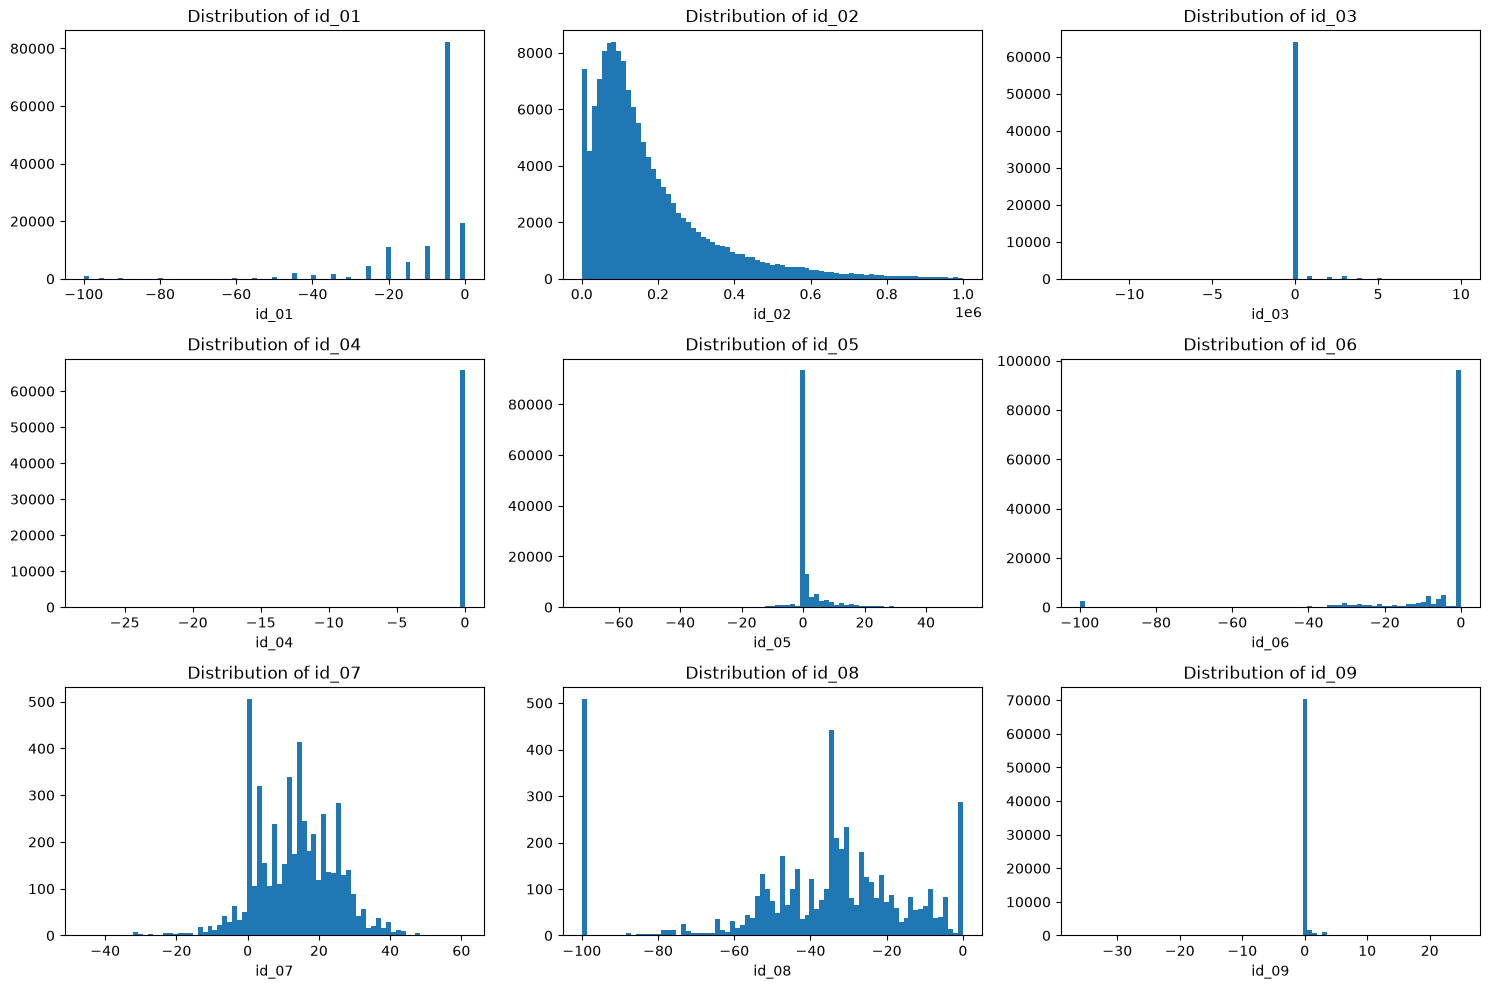

In [53]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

axes = axes.flatten()

for i in range(9):
    col = f'id_{i+1:02d}'

    axes[i].hist(train_dataset[col].dropna(), bins=77)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

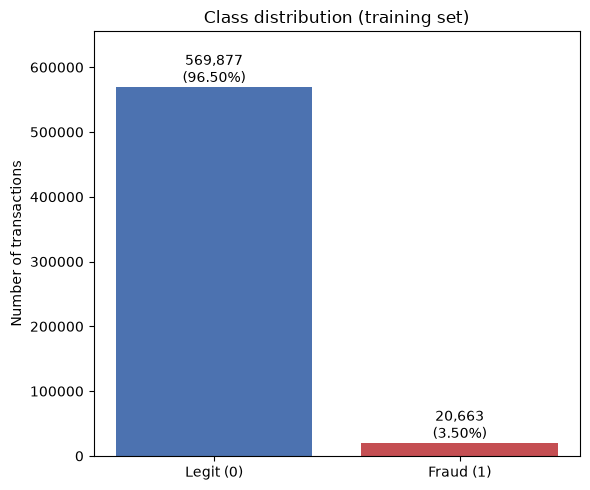

In [54]:
counts = train_dataset["isFraud"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(["Legit (0)", "Fraud (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}\n({value / counts.sum():.2%})",
            ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Class distribution (training set)")
ax.set_ylabel("Number of transactions")
plt.tight_layout();

In [55]:
for i in range(9):
    col = f'id_{i+1:02d}'
    print(train_dataset[col].value_counts(dropna=False, normalize=True).head())

id_01
 NaN     0.755761
-5.0     0.139144
 0.0     0.033114
-10.0    0.019062
-20.0    0.018984
Name: proportion, dtype: float64
id_02
NaN       0.761452
1102.0    0.000019
696.0     0.000017
1120.0    0.000015
1083.0    0.000015
Name: proportion, dtype: float64
id_03
NaN    0.887689
0.0    0.108211
1.0    0.001461
3.0    0.001131
2.0    0.000713
Name: proportion, dtype: float64
id_04
 NaN    0.887689
 0.0    0.111320
-5.0    0.000224
-6.0    0.000166
-8.0    0.000108
Name: proportion, dtype: float64
id_05
NaN    0.768238
0.0    0.157048
1.0    0.014043
2.0    0.008360
3.0    0.006526
Name: proportion, dtype: float64
id_06
 NaN    0.768238
 0.0    0.154647
-1.0    0.007937
-5.0    0.006518
-6.0    0.005515
Name: proportion, dtype: float64
id_07
NaN     0.991271
0.0     0.000693
16.0    0.000415
14.0    0.000386
12.0    0.000352
Name: proportion, dtype: float64
id_08
 NaN      0.991271
-100.0    0.000847
 0.0      0.000442
-34.0     0.000435
-33.0     0.000354
Name: proportion, dtype: f

Text(0.5, 1.0, 'Distribution of transactiond dates')

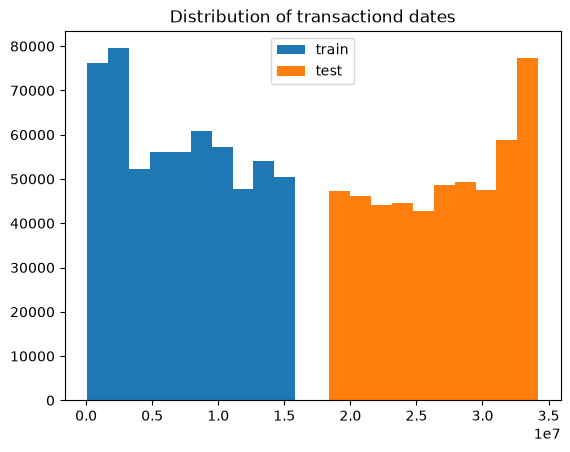

In [56]:
plt.hist(train_dataset['TransactionDT'], label='train')
plt.hist(test_dataset['TransactionDT'], label='test')
plt.legend()
plt.title('Distribution of transactiond dates')

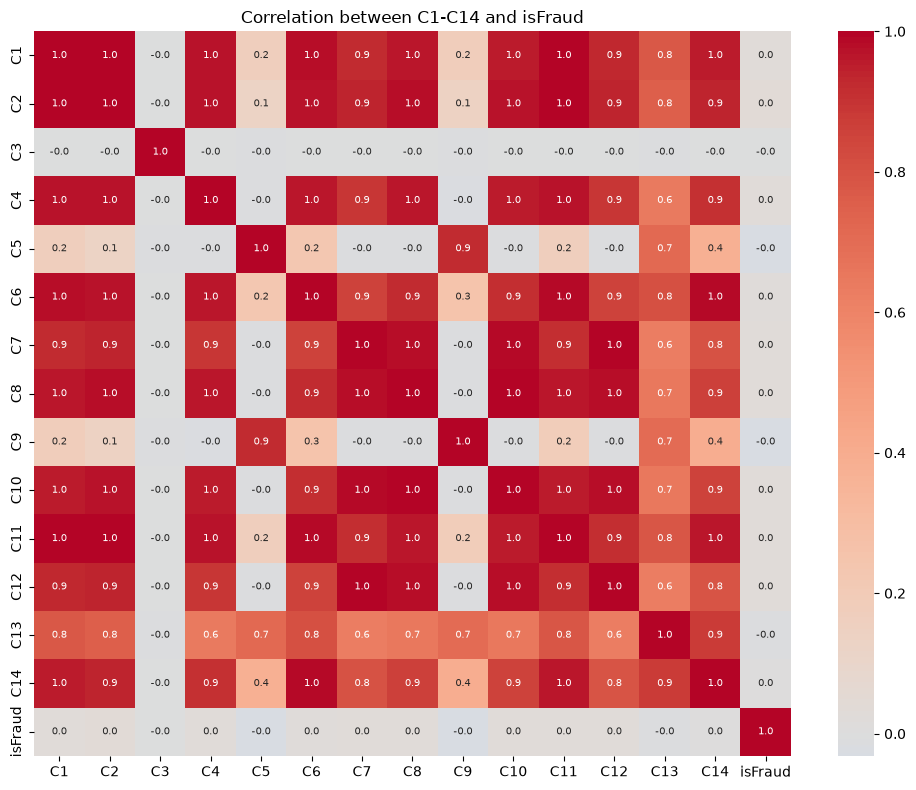

In [57]:
c_cols = [f"C{i}" for i in range(1, 15)]
plt.figure(figsize=(10, 8))
sns.heatmap(train_dataset[c_cols + ["isFraud"]].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7})
plt.title("Correlation between C1-C14 and isFraud")
plt.tight_layout();

percentage of missing values in each feature

In [58]:
missing_pct = train_dataset.isnull().mean() * 100

missing_df = (
    missing_pct.sort_values(ascending=False)
)

display(missing_df.head(20))

id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
dtype: float64

Identify columns with more than 90% missing values

In [59]:
cols_to_drop = missing_pct[
    missing_pct > 90
].index

print("Columns being removed:", len(cols_to_drop))

# Remove those columns
train_dataset.drop(
    columns=cols_to_drop,
    inplace=True
)

print("New shape:", train_dataset.shape)

Columns being removed: 12
New shape: (590540, 422)


Count categorical and numerical features

In [60]:
print(
    "Categorical columns:",
    train_dataset.select_dtypes(include=['object']).shape[1]
)

print(
    "Numerical columns:",
    train_dataset.select_dtypes(include=['number']).shape[1]
)

Categorical columns: 29
Numerical columns: 393


C:\Users\huuth\AppData\Local\Temp\ipykernel_26824\345240180.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_dataset.select_dtypes(include=['object']).shape[1]


In [61]:
numeric_train = train_dataset.select_dtypes(include = ["number"]).copy()
numeric_train.shape

(590540, 393)

Separate predictors and target

In [62]:
X = numeric_train.drop(
    columns=['isFraud', 'TransactionID'],
    errors='ignore'
)

y = numeric_train['isFraud']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (590540, 391)
Target shape: (590540,)


Replace missing values using median imputation

In [63]:
imputer = SimpleImputer(
    strategy='median'
)

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print(
    "Remaining missing values:",
    X.isnull().sum().sum()
)

Remaining missing values: 0


Splitting dataset

In [64]:
# Sort by time so the split keeps the time order
train_dataset = train_dataset.sort_values("TransactionDT").reset_index(drop=True)

#80% (train + validation) and 20% test
train_val_df, test_df = train_test_split(train_dataset, test_size=0.2, shuffle=False)

#25% of the remaining 80% = 20% of all data for validation
train_df, valid_df = train_test_split(train_val_df, test_size=0.25, shuffle=False)



y_train = train_df["isFraud"].values
y_valid = valid_df["isFraud"].values
y_test = test_df["isFraud"].values

for name, y in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(f"{name}: {len(y):,} rows, fraud rate {y.mean():.2%}")

Train: 354,324 rows, fraud rate 3.38%
Validation: 118,108 rows, fraud rate 3.90%
Test: 118,108 rows, fraud rate 3.44%


Selecting columns for numeric, categoric(low card columns & high card columns)

In [65]:
ID_COLS = ["TransactionID", "TransactionDT", "isFraud"]

cat_cols = [c for c in train_df.columns if not pd.api.types.is_numeric_dtype(train_df[c])]
num_cols = [c for c in train_df.columns if c not in cat_cols and c not in ID_COLS]
low_card_cols = [c for c in cat_cols if train_df[c].nunique() <= 10]
high_card_cols = [c for c in cat_cols if train_df[c].nunique() > 10]

print(f"Numeric: {len(num_cols)} | Low-card text: {len(low_card_cols)} | High-card text: {len(high_card_cols)}")

Numeric: 390 | Low-card text: 23 | High-card text: 6


Create a pipepline for preprocessing features

In [66]:
# Numeric columns: fill missing with median -> scale
numeric_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Text columns with few categories: fill missing with "missing" -> one-hot
low_card_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)),
])

# Text columns with many categories: fill missing -> one-hot of the top 19 + "other"
high_card_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(max_categories=20, handle_unknown="infrequent_if_exist",
                             sparse_output=False, dtype=np.float32)),
])

# Send each group of columns to its pipeline
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("low", low_card_pipeline, low_card_cols),
    ("high", high_card_pipeline, high_card_cols),
], verbose_feature_names_out=False)

Apply a preprocessing step to dataset 

In [67]:
X_train = preprocessor.fit_transform(train_df)   # learn medians/categories/scaling from TRAIN + apply
X_valid = preprocessor.transform(valid_df)       # apply only (no learning)
X_test = preprocessor.transform(test_df)         # apply only (no learning)

feature_names = preprocessor.get_feature_names_out()

print("X_train:", X_train.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)
print("Missing values left:", np.isnan(X_train).sum())
print("Example new columns:", [n for n in feature_names if n.startswith("P_emaildomain")][:6])

X_train: (354324, 589) | X_valid: (118108, 589) | X_test: (118108, 589)
Missing values left: 0
Example new columns: ['P_emaildomain_anonymous.com', 'P_emaildomain_aol.com', 'P_emaildomain_att.net', 'P_emaildomain_bellsouth.net', 'P_emaildomain_comcast.net', 'P_emaildomain_cox.net']


Training the models and save a best model in a results dictionary

In [68]:

# How many legit transactions per fraud (used to weight fraud more)
fraud_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "LogisticRegression":LogisticRegression(max_iter=1000, class_weight="balanced"),

    "RandomForestClassifier": RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                            max_features="sqrt", class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=42),

    "XGBClassifier": XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=8,
                             subsample=0.8, colsample_bytree=0.5,
                             scale_pos_weight=fraud_weight, tree_method="hist",
                             eval_metric="aucpr", n_jobs=-1, random_state=42),

    "LGBClassifier": LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=64,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                               class_weight="balanced", n_jobs=-1, random_state=42, verbose=-1),
}

def best_threshold(y_true, proba):
    # Try every threshold and keep the one with the highest F1
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]

results = []
trained_models = {}

for name, clf in models.items():
    pipe = Pipeline(steps =[
        ("preprocess", clone(preprocessor)),
        ("classifier", clf),
        ])

    pipe.fit(train_df, y_train)                     

    # Choose the threshold on VALIDATION, then score on TEST
    threshold = best_threshold(y_valid, pipe.predict_proba(valid_df)[:, 1])
    proba_test = pipe.predict_proba(test_df)[:, 1]
    pred_test = (proba_test >= threshold).astype(int)

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_test, proba_test),
        "ROC-AUC": roc_auc_score(y_test, proba_test),
        "Precision": precision_score(y_test, pred_test),
        "Recall": recall_score(y_test, pred_test),
        "F1": f1_score(y_test, pred_test),
        "Threshold": threshold,
    })
    trained_models[name] = pipe
    print(f"{name:20s} PR-AUC {results[-1]['PR-AUC']:.4f} | F1 {results[-1]['F1']:.4f}")

results_df = pd.DataFrame(results).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
print(f"\nRandom-guess PR-AUC: {y_test.mean():.4f}")
results_df.round(4)

LogisticRegression   PR-AUC 0.1925 | F1 0.3291
RandomForestClassifier PR-AUC 0.4582 | F1 0.4567
XGBClassifier        PR-AUC 0.4785 | F1 0.4710
LGBClassifier        PR-AUC 0.4899 | F1 0.4779

Random-guess PR-AUC: 0.0344


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Threshold
0,LGBClassifier,0.4899,0.8809,0.5440,0.4262,0.4779,0.7387
1,XGBClassifier,0.4785,0.8729,0.5164,0.4328,0.4710,0.6832
2,RandomForestClassifier,0.4582,0.8724,0.5417,0.3947,0.4567,0.4497
3,LogisticRegression,0.1925,0.8236,0.3011,0.3629,0.3291,0.8710


Getting an importance features

In [69]:
def get_importance(pipe):
    feature_names = pipe.named_steps["preprocess"].get_feature_names_out()
    model = pipe.named_steps["classifier"]

    if type(model).__name__ == "LGBMClassifier":
        values = model.booster_.feature_importance(importance_type="gain")   # gain, not split count
    elif hasattr(model, "feature_importances_"):
        values = model.feature_importances_                                   # Random Forest, XGBoost
    else:
        values = np.abs(model.coef_[0])                                       # Logistic Regression

    importance = pd.Series(values, index=feature_names)
    return (importance / importance.sum()).sort_values(ascending=False)       # share of total, sums to 1


importances = {name: get_importance(pipe) for name, pipe in trained_models.items()}

for name, imp in importances.items():
    print(f"\n{name} - top 10")
    print(imp.head(10).round(4).to_string())


LogisticRegression - top 10
C11                                  0.0398
DeviceInfo_hi6210sft Build/MRA58K    0.0373
C14                                  0.0324
C4                                   0.0188
V168                                 0.0124
C6                                   0.0120
R_emaildomain_msn.com                0.0105
R_emaildomain_bellsouth.net          0.0105
DeviceInfo_SM-G930V Build/NRD90M     0.0096
id_33_2560x1440                      0.0095

RandomForestClassifier - top 10
C13               0.0306
TransactionAmt    0.0230
C14               0.0219
card1             0.0190
card2             0.0174
C4                0.0143
C5                0.0139
addr1             0.0134
C10               0.0131
D2                0.0126

XGBClassifier - top 10
V258           0.0531
V257           0.0463
V218           0.0317
V219           0.0269
V294           0.0223
V91            0.0213
V70            0.0199
V295           0.0167
ProductCD_W    0.0116
V264           0.0112

LGB

Visualizing an importance features for each model

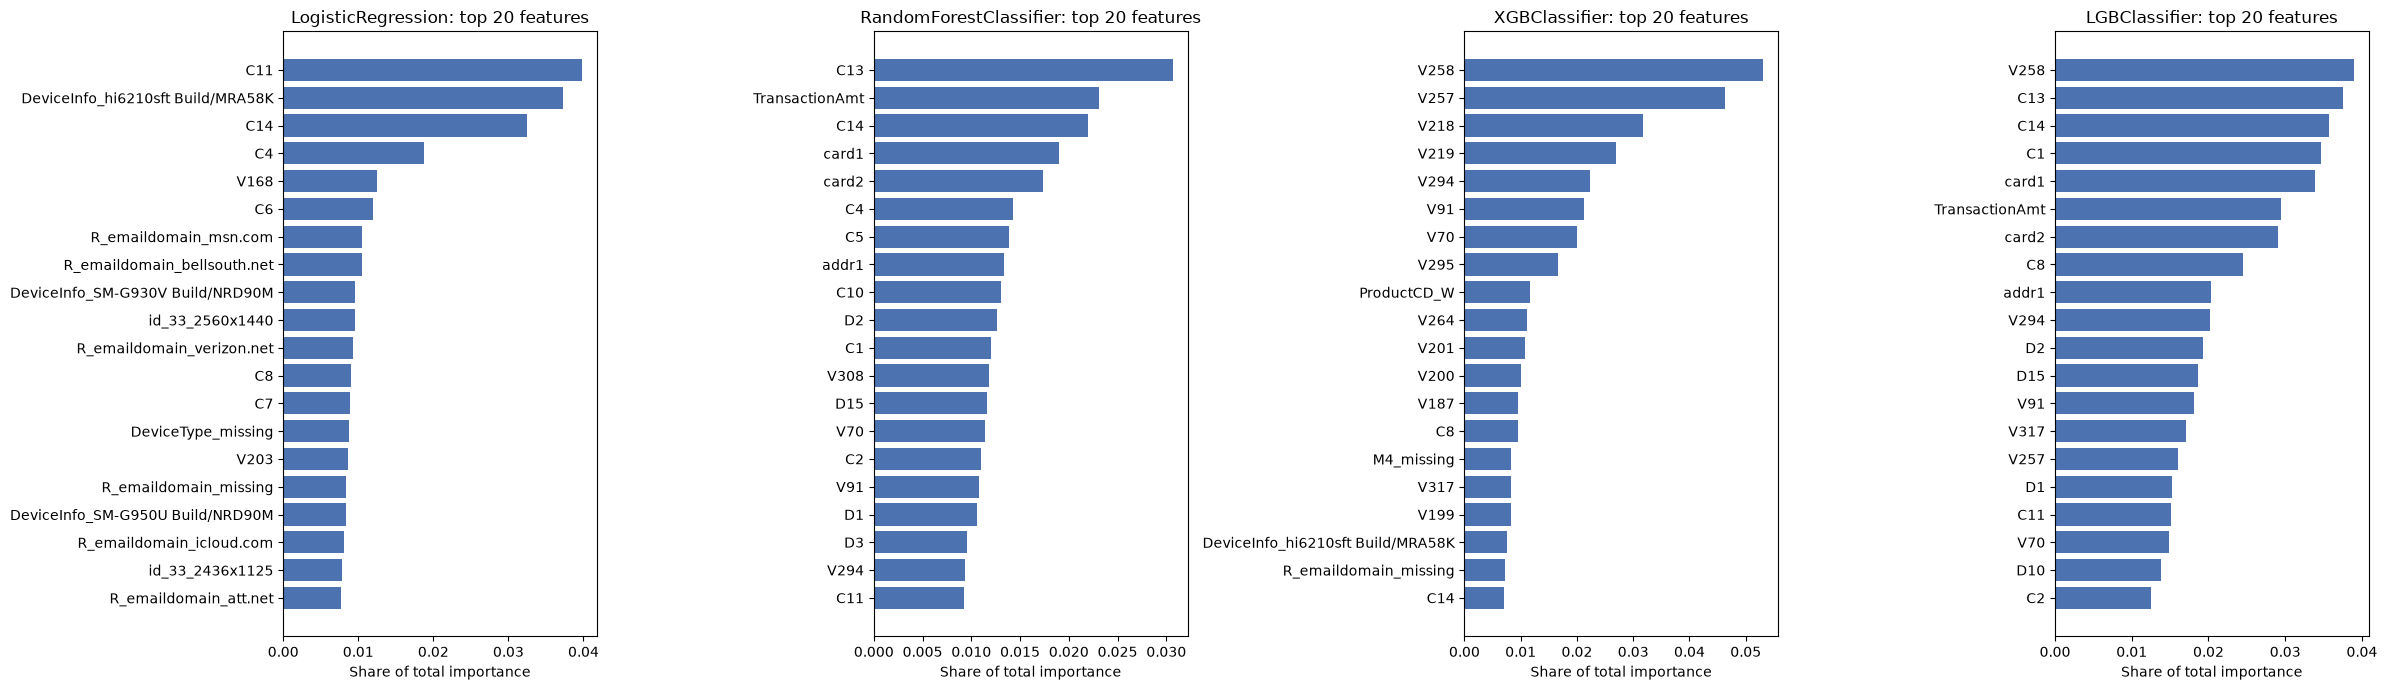

In [70]:
n_models = len(importances)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 7))
axes = np.atleast_1d(axes)

for ax, (name, imp) in zip(axes, importances.items()):
    top20 = imp.head(20)[::-1]
    ax.barh(top20.index, top20.values, color="#4C72B0")
    ax.set_title(f"{name}: top 20 features")
    ax.set_xlabel("Share of total importance")

plt.tight_layout()
plt.savefig("feature_importance_top20.png", dpi=200)
plt.show()

Visualizing an importance model for all models

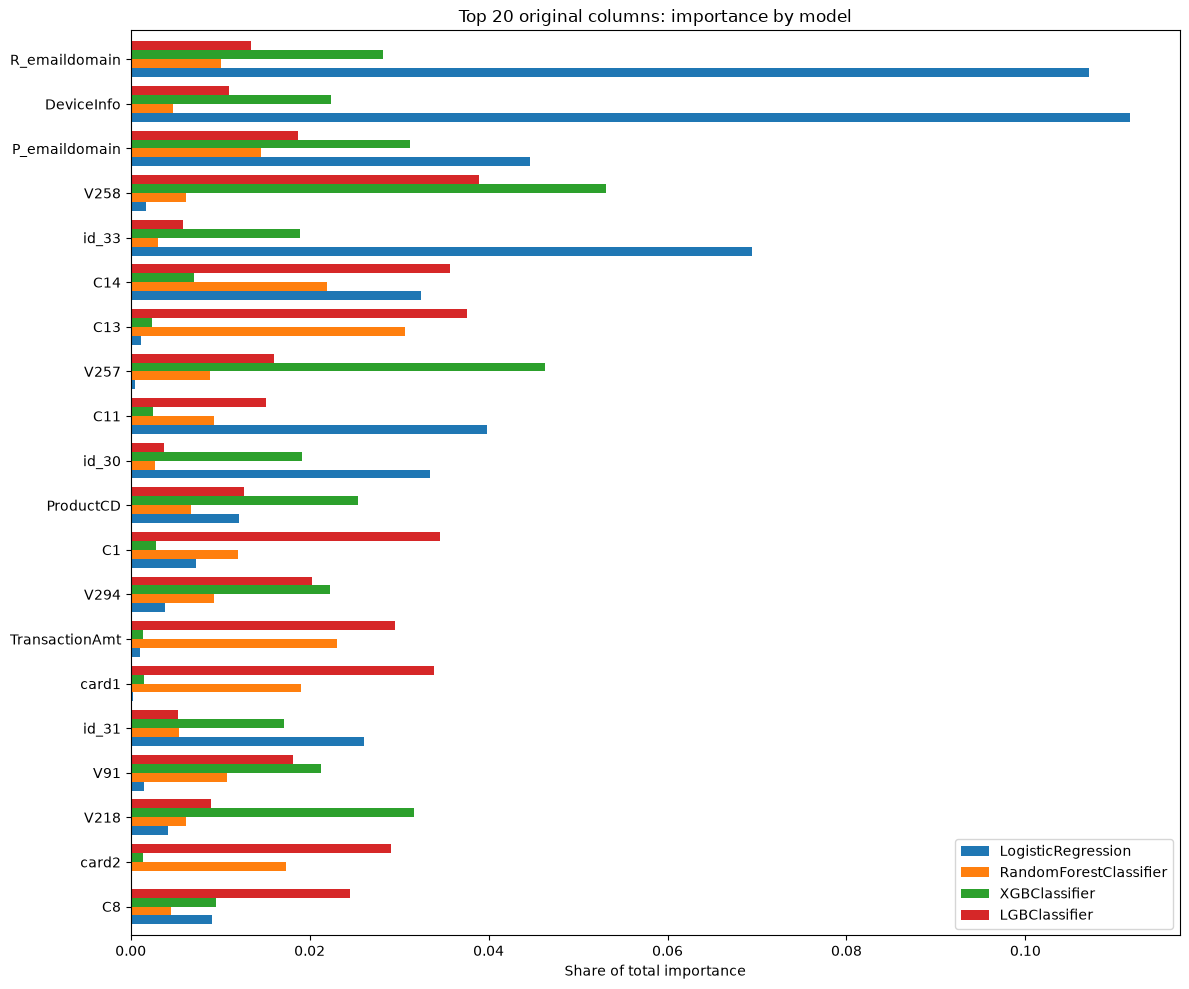

                LogisticRegression  RandomForestClassifier  XGBClassifier  \
R_emaildomain               0.1071                  0.0100         0.0282   
DeviceInfo                  0.1117                  0.0047         0.0224   
P_emaildomain               0.0447                  0.0145         0.0312   
V258                        0.0017                  0.0062         0.0531   
id_33                       0.0695                  0.0030         0.0189   
C14                         0.0324                  0.0219         0.0071   
C13                         0.0011                  0.0306         0.0024   
V257                        0.0004                  0.0088         0.0463   
C11                         0.0398                  0.0093         0.0025   
id_30                       0.0335                  0.0027         0.0192   
ProductCD                   0.0121                  0.0067         0.0254   
C1                          0.0072                  0.0120         0.0029   

In [71]:
original_cols = num_cols + low_card_cols + high_card_cols

def to_original_column(feature_name):
    if feature_name in original_cols:
        return feature_name
    matches = [c for c in original_cols if feature_name.startswith(c + "_")]
    return max(matches, key=len)

grouped = pd.DataFrame({
    name: imp.groupby(imp.index.map(to_original_column)).sum()
    for name, imp in importances.items()
})
grouped["Average"] = grouped.mean(axis=1)
grouped = grouped.sort_values("Average", ascending=False)

top_cols = grouped.head(20).index[::-1]
ax = grouped.loc[top_cols, list(importances.keys())].plot(kind="barh", figsize=(12, 10), width=0.8)
ax.set_title("Top 20 original columns: importance by model")
ax.set_xlabel("Share of total importance")
plt.tight_layout()
plt.savefig("feature_importance_by_column.png", dpi=200)
plt.show()

print(grouped.head(20).round(4))